<a href="https://colab.research.google.com/github/Mattchow041123/Sign-Language-Alphabet-Recognizer/blob/main/Sign_Language_Alphabet_Recognizer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import PIL
import gradio as gr

print("All libraries are ready!")

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Gradio:", gr.__version__)

All libraries are ready!
TensorFlow: 2.21.0
NumPy: 2.4.6
Gradio: 6.31.0


In [ ]:
from google.colab import files

uploaded = files.upload()

In [ ]:
import os
import shutil

os.makedirs('/root/.kaggle', exist_ok=True)

shutil.copy(
    '/content/kaggle.json',
    '/root/.kaggle/kaggle.json'
)

os.chmod('/root/.kaggle/kaggle.json', 0o600)

print("Kaggle API configured successfully!")

FileNotFoundError: [Errno 2] No such file or directory: '/content/kaggle.json'

In [ ]:
!pip install -q kaggle

In [ ]:
!kaggle datasets list -s "sign-language-mnist"

You must authenticate before you can call the Kaggle API.
Follow the instructions to authenticate at: https://github.com/Kaggle/kaggle-cli/blob/main/docs/README.md#authentication


In [ ]:
!kaggle datasets download -d datamunge/sign-language-mnist

Dataset URL: https://www.kaggle.com/datasets/datamunge/sign-language-mnist
License(s): CC0-1.0
100% 62.6M/62.6M [00:04<00:00, 16.2MB/s]



In [ ]:
import zipfile
import os

zip_path = '/content/sign-language-mnist.zip'
extract_path = '/content/sign_language_dataset'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [ ]:
import os

extract_path = '/content/sign_language_dataset'

print("Extracted files:")

for file in os.listdir(extract_path):
    print(file)

Extracted files:
amer_sign2.png
sign_mnist_train.csv
sign_mnist_train
sign_mnist_test
amer_sign3.png
american_sign_language.PNG
sign_mnist_test.csv


In [ ]:
import pandas as pd

train_path = '/content/sign_language_dataset/sign_mnist_train.csv'
test_path = '/content/sign_language_dataset/sign_mnist_test.csv'

train_data = pd.read_csv(train_path)
test_data = pd.read_csv(test_path)

print("Training dataset:", train_data.shape)
print("Testing dataset:", test_data.shape)

display(train_data.head())

Training dataset: (27455, 785)
Testing dataset: (7172, 785)


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,3,107,118,127,134,139,143,146,150,153,...,207,207,207,207,206,206,206,204,203,202
1,6,155,157,156,156,156,157,156,158,158,...,69,149,128,87,94,163,175,103,135,149
2,2,187,188,188,187,187,186,187,188,187,...,202,201,200,199,198,199,198,195,194,195
3,2,211,211,212,212,211,210,211,210,210,...,235,234,233,231,230,226,225,222,229,163
4,13,164,167,170,172,176,179,180,184,185,...,92,105,105,108,133,163,157,163,164,179


In [ ]:
# Separate labels from image pixels

X_train = train_data.drop('label', axis=1)
y_train = train_data['label']

X_test = test_data.drop('label', axis=1)
y_test = test_data['label']

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)

print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

Training images: (27455, 784)
Training labels: (27455,)
Testing images: (7172, 784)
Testing labels: (7172,)


In [ ]:
# Normalize pixel values

X_train = X_train / 255.0
X_test = X_test / 255.0

print("Minimum pixel value:", X_train.min().min())
print("Maximum pixel value:", X_train.max().max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [ ]:
print("Image height: 28")
print("Image width: 28")
print("Total pixels:", 28 * 28)

Image height: 28
Image width: 28
Total pixels: 784


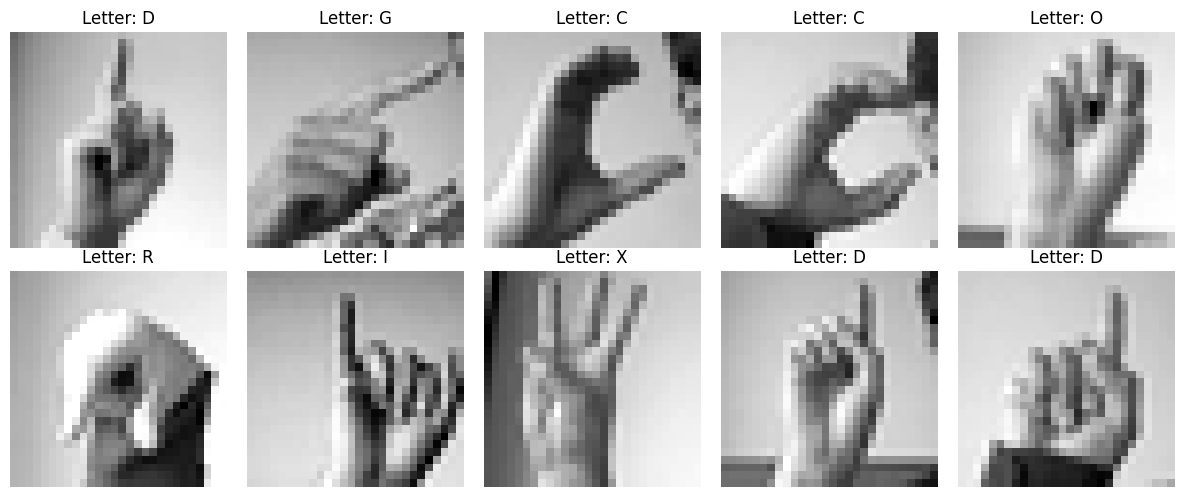

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

# Convert numerical labels into alphabet letters
def label_to_letter(label):
    if label >= 9:
        label += 1
    return chr(label + 65)

# Display 10 random training images
plt.figure(figsize=(12, 5))

for i in range(10):
    image = X_train.iloc[i].values.reshape(28, 28)
    label = y_train.iloc[i]

    plt.subplot(2, 5, i + 1)
    plt.imshow(image, cmap='gray')
    plt.title("Letter: " + label_to_letter(label))
    plt.axis('off')

plt.tight_layout()
plt.show()


In [ ]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (27455, 784)
y_train: (27455,)
X_test: (7172, 784)
y_test: (7172,)


In [ ]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

print("TensorFlow imported successfully!")

TensorFlow imported successfully!


In [ ]:
import numpy as np

X_train = np.asarray(X_train, dtype='float32')
X_test = np.asarray(X_test, dtype='float32')

y_train = np.asarray(y_train, dtype='int32')
y_test = np.asarray(y_test, dtype='int32')

print("Data converted successfully!")
print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)

Data converted successfully!
Training images: (27455, 784)
Testing images: (7172, 784)


In [ ]:
model = Sequential([

    # Input layer
    tf.keras.Input(shape=(784,)),

    # First hidden layer
    Dense(256, activation='relu'),

    # Dropout to reduce overfitting
    Dropout(0.3),

    # Second hidden layer
    Dense(128, activation='relu'),

    # Output layer
    Dense(25, activation='softmax')

])

print("MLP model created successfully!")

MLP model created successfully!


In [ ]:
model.compile(

    optimizer='adam',

    loss='sparse_categorical_crossentropy',

    metrics=['accuracy']

)

print("Model compiled successfully!")

Model compiled successfully!


In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 25)             │         3,225 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 237,081 (926.10 KB)

 Trainable params: 237,081 (926.10 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow version: 2.21.0
Libraries imported successfully!


In [ ]:
model = Sequential([
    tf.keras.Input(shape=(784,)),

    Dense(256, activation='relu'),

    Dropout(0.3),

    Dense(128, activation='relu'),

    Dense(25, activation='softmax')
])

print("MLP model created successfully!")

MLP model created successfully!


In [ ]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 25)             │         3,225 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 237,081 (926.10 KB)

 Trainable params: 237,081 (926.10 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/15
687/687 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.2569 - loss: 2.3791 - val_accuracy: 0.5445 - val_loss: 1.5278
Epoch 2/15
687/687 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.4677 - loss: 1.5897 - val_accuracy: 0.6330 - val_loss: 1.1078
Epoch 3/15
687/687 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.5557 - loss: 1.3024 - val_accuracy: 0.6908 - val_loss: 0.9959
Epoch 4/15
687/687 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.6141 - loss: 1.1190 - val_accuracy: 0.7864 - val_loss: 0.7165
Epoch 5/15
687/687 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.6509 - loss: 1.0081 - val_accuracy: 0.8048 - val_loss: 0.6282
Epoch 6/15
687/687 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6899 - loss: 0.8795 - val_accuracy: 0.8343 - val_loss: 0.5174
Epoch 7/15
687/687 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7108 - loss: 0.8187 - val_accuracy: 0.8738 - val_loss: 0.4187
Epoch 8/15
687/687 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7245 - loss: 0.7712 - val_accuracy: 0.

In [ ]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Accuracy:", test_accuracy * 100, "%")
print("Test Loss:", test_loss)

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7264 - loss: 0.9543
Test Accuracy: 72.64361381530762 %
Test Loss: 0.9542663097381592


In [ ]:
from sklearn.metrics import classification_report
import numpy as np

y_pred = np.argmax(model.predict(X_test), axis=1)

def label_to_letter(label):
    if label >= 9:
        label += 1
    return chr(label + 65)

labels = sorted(np.unique(y_test))

target_names = [
    label_to_letter(int(label))
    for label in labels
]

print(classification_report(
    y_test,
    y_pred,
    labels=labels,
    target_names=target_names
))

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
              precision    recall  f1-score   support

           A       0.83      0.94      0.88       331
           B       0.96      0.95      0.96       432
           C       0.99      0.90      0.94       310
           D       0.90      1.00      0.95       245
           E       0.74      0.88      0.80       498
           F       0.76      0.83      0.80       247
           G       0.87      0.79      0.83       348
           H       0.95      0.92      0.94       436
           I       0.72      0.69      0.70       288
           L       0.78      0.50      0.61       331
           M       0.64      1.00      0.78       209
           N       1.00      0.25      0.40       394
           O       0.43      0.64      0.52       291
           P       0.93      0.58      0.71       246
           Q       0.95      1.00      0.97       347
           R       0.63      0.87      0.73       164
           S       0.28      0.57      0

<Figure size 1400x1400 with 0 Axes>

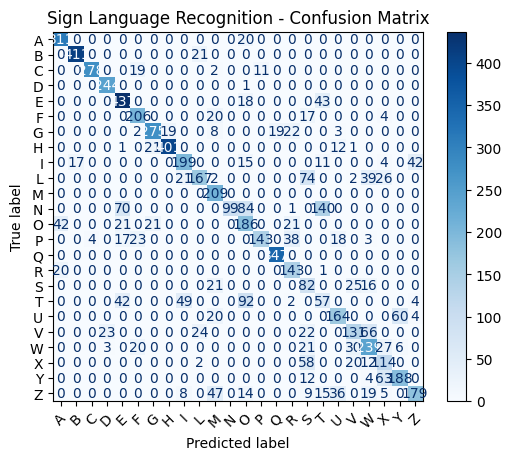

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred, labels=labels)

display_labels = [
    label_to_letter(int(label))
    for label in labels
]

plt.figure(figsize=(14, 14))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=display_labels
)

disp.plot(
    cmap='Blues',
    xticks_rotation=45,
    values_format='d'
)

plt.title("Sign Language Recognition - Confusion Matrix")
plt.show()